In [2]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
from tqdm import tqdm

import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.visualization as vis
import utils.util_machine_learning as uml

import SimpleITK as sitk
import test_code.dfield_approach_elastix.constants as cts
# import metrics_computer as metrics_computer
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from scipy import stats

from features_loader import FeaturesLoader

np.set_printoptions(precision=4)


SERVER: False


# Important itssues

# Important regions of the brain

- **lateral ventricles** (R:43, L:4)
- **hipocampus** (R:53, L:17)
- **thalamus** (R:49, L:10)
- **cortex** (R:42, L:3)
    - entorhinal cortex (R:2006, L:1006)
    - inferior temporal gyri (R:2009, L:1009)
    - superior parietal (R:2029, L:1029)
    - middle frontal gyrus (R:2027, L:1027)
    - superior frontal gyrus (R:2028, L:1028)
    - precuneus (R:2025, L:1025)
    - cuneus (R:2005, L:1005)

**Other founds:**
- 3rd ventricle (14)


In [3]:
IMPORTANT_TISSUES = [43, 4, 53, 17, 49, 10, 42, 3, 2006, 1006, 2009, 1009, 2029, 1029, 2027, 1027, 2028, 1028, 2025, 1025, 2005, 1005, 14]
print(len(IMPORTANT_TISSUES))

23


# Load data

,patient_id,0_dice,1_dice,2_dice,3_dice
366,8202.0,0.995506,0.921223,0.866655,0.937254
621,14098.0,0.994619,0.954911,0.854318,0.931207
622,14104.0,0.994629,0.970336,0.863733,0.934710
623,14128.0,0.995636,0.931638,0.873874,0.937639
624,14135.0,0.995218,0.931816,0.870036,0.937107


patient_id    7849.565918
0_dice           0.995158
1_dice           0.945827
2_dice           0.868819
3_dice           0.936689
dtype: float32


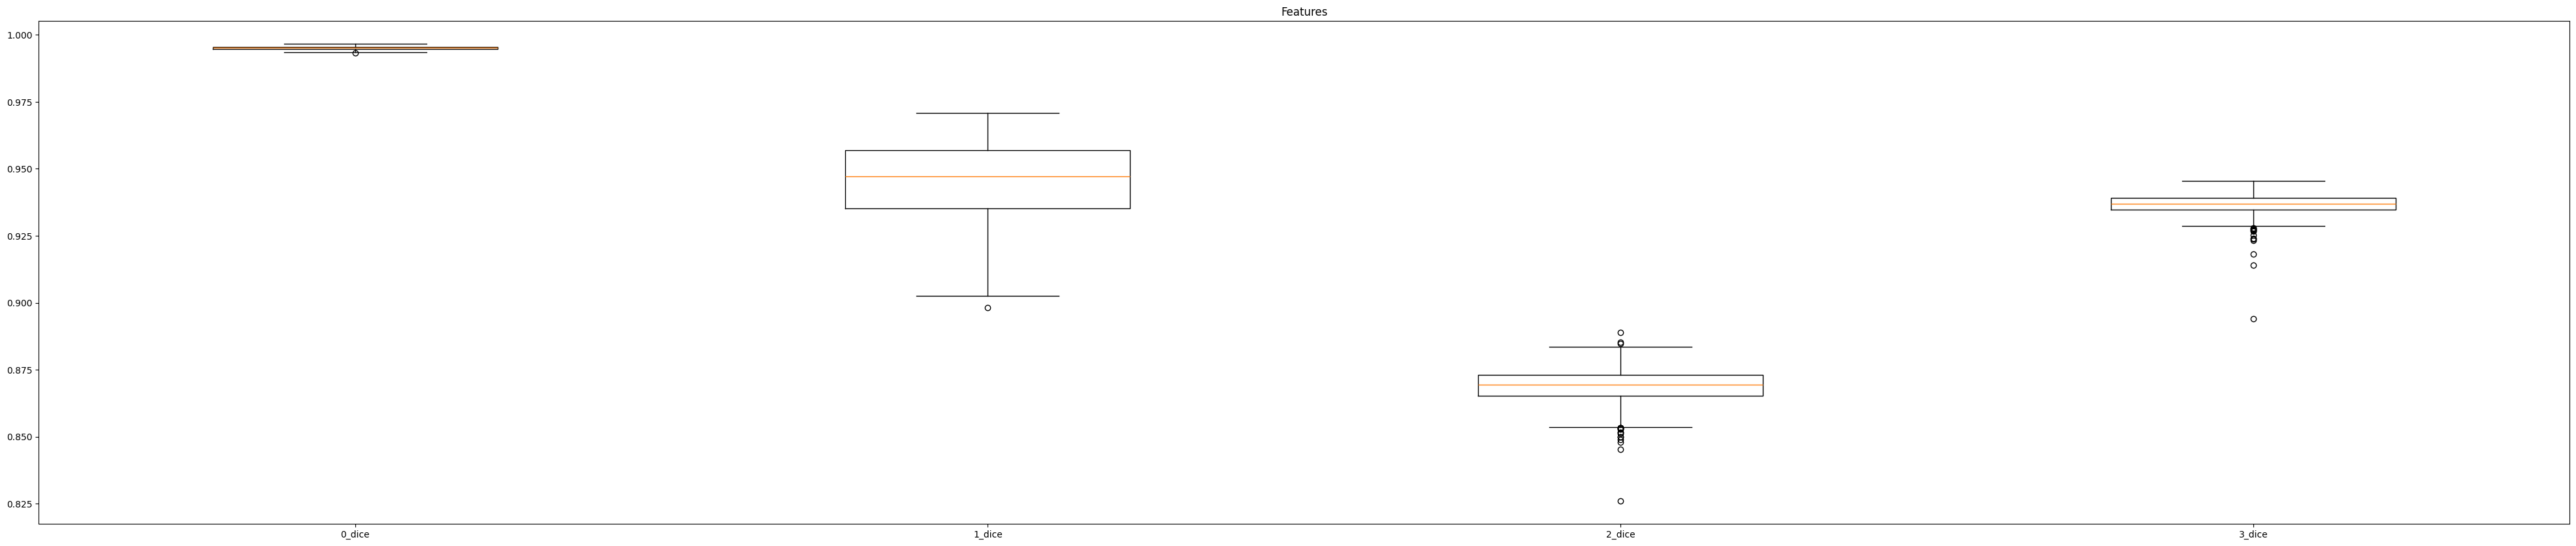

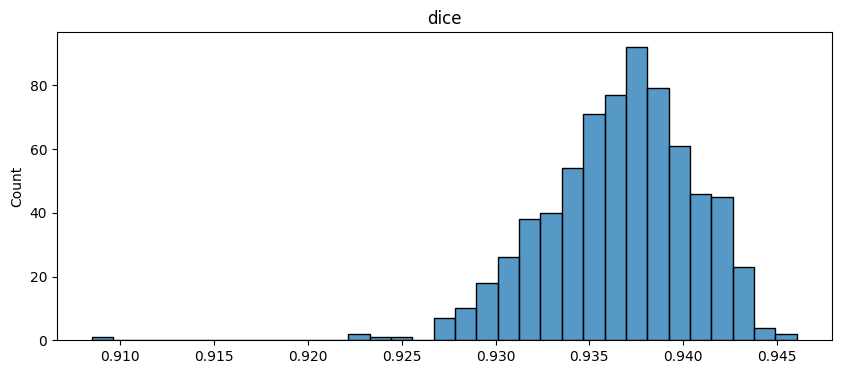

In [4]:
nb_tissues = 3
metrics_name = ['dice']

matching_ids = pil.get_matching_ids()
reader = FeaturesLoader(nb_tissues, matching_ids)
# data = reader.get_df(tissue_ids=IMPORTANT_TISSUES, metrics_name=metrics_name, remove_tissues=False, remove_metrics=False, return_patient_id=True, id_patients=pil.EXCLUDED_PATIENTS, remove_patients=True)
data = reader.get_df(tissue_ids=None, metrics_name=metrics_name, remove_tissues=False, remove_metrics=False, return_patient_id=True, id_patients=pil.EXCLUDED_PATIENTS, remove_patients=True)
# data = reader.get_df(tissue_ids=IMPORTANT_TISSUES, metrics_name=['vol_diff_perc', 'jac_mean'], remove_tissues=False, remove_metrics=False, return_patient_id=True, id_patients=pil.EXCLUDED_PATIENTS, remove_patients=True)
# data = reader.get_df(tissue_ids=IMPORTANT_TISSUES, metrics_name=['jac_mean', 'div_mean', 'mag_mean'], remove_tissues=False, remove_metrics=False, return_patient_id=False, id_patients=pil.EXCLUDED_PATIENTS, remove_patients=True)
# data = reader.get_df(tissue_ids=[0], metrics_name=None, remove_tissues=True, remove_metrics=False, return_patient_id=False)

val_ids = [int(i) for i in ["08202"] + pil.get_matching_ids()[621:]]
indices = data[data['patient_id'].isin(val_ids)].index
display(data.loc[indices].head())
print(data.mean())


data_ids = data.pop('patient_id').tolist()
data_columns = data.columns.tolist()


vis.plot_data_voxplot(data, data_columns, figsize=(50,10))

# vis.plot_hist_all_data_df(data, bins="auto", binrange=None, figsize=(10, 4))

column_means = data.mean(axis=1)
vis.plot_hist(column_means, "dice", bins="auto", kde=False, binrange=None, figsize=(10, 4))


# Preprocessing

### Remove outlayers

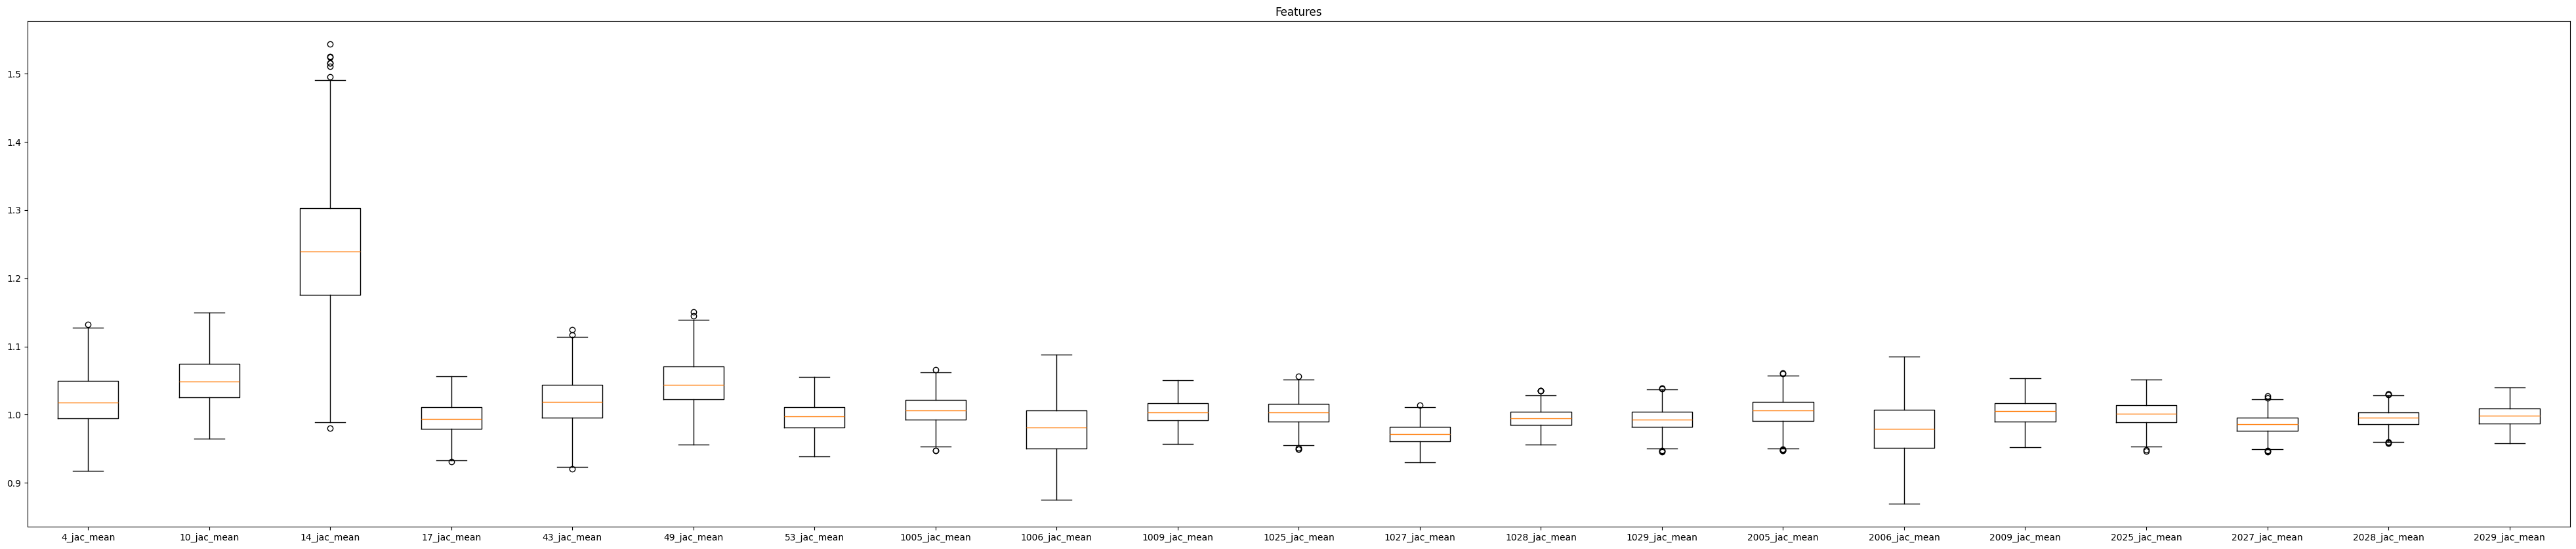

In [14]:
# def remove_outliers_zscore(data, threshold=3):
#     z_scores = stats.zscore(data)
#     abs_z_scores = np.abs(z_scores)
#     filtered_data = data[(abs_z_scores < threshold).all(axis=1)]
#     return filtered_data

data_no_outlayers, no_outlayers_index, outlayers_index = uml.remove_outliers_zscore(data.values, threshold=2.5)

# data_no_outlayers = remove_outliers_zscore(data, threshold=2.5)
vis.plot_data_voxplot(data_no_outlayers, data_columns, figsize=(50,10))

### Standarize and normalize

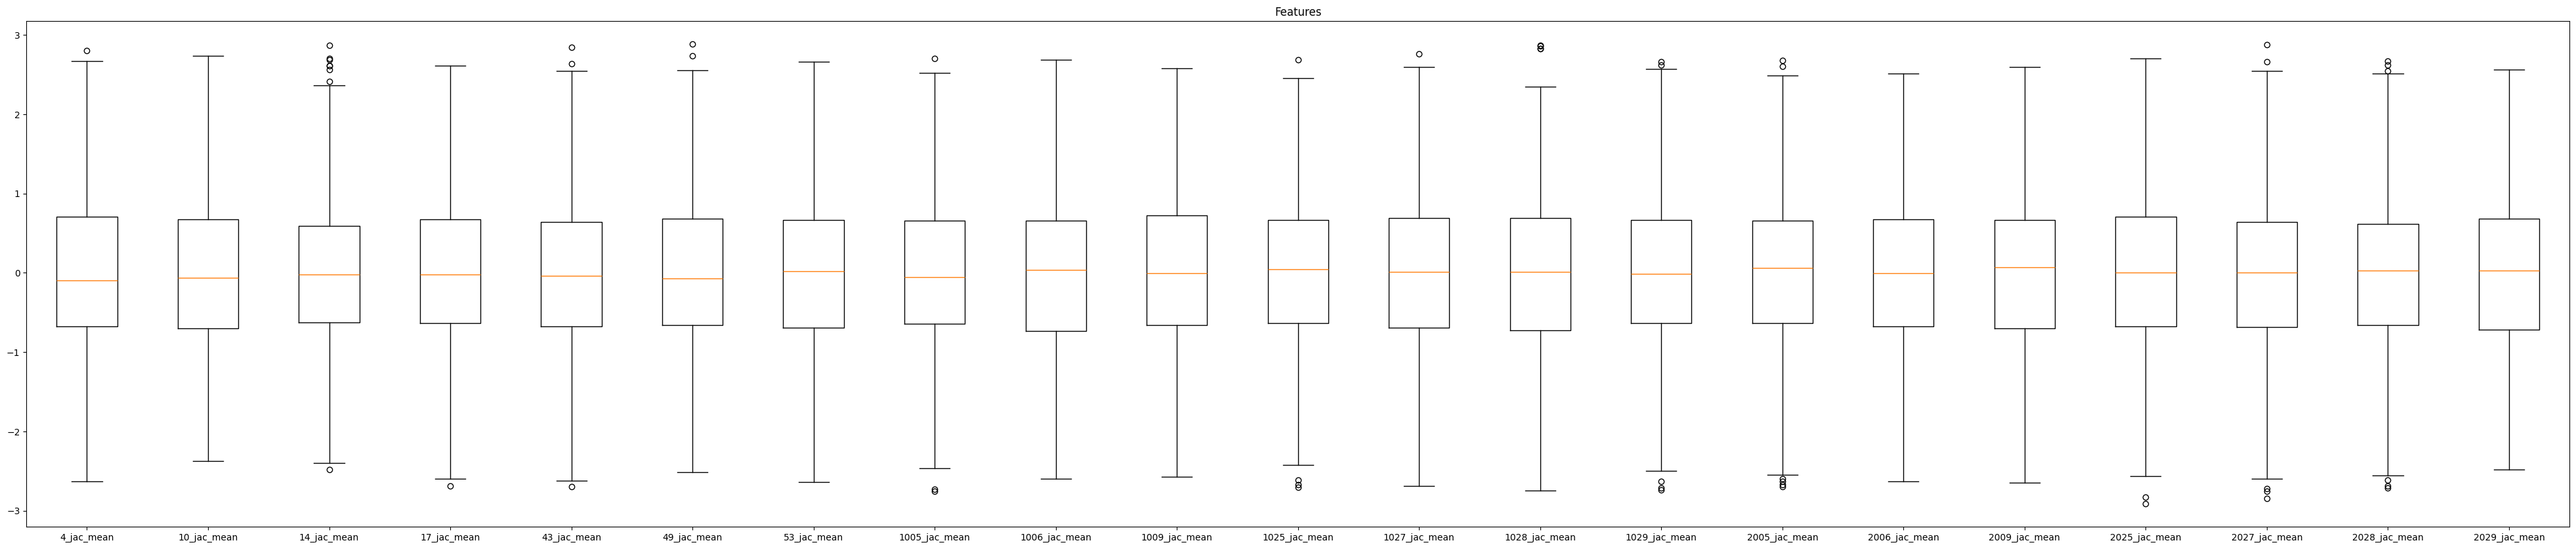

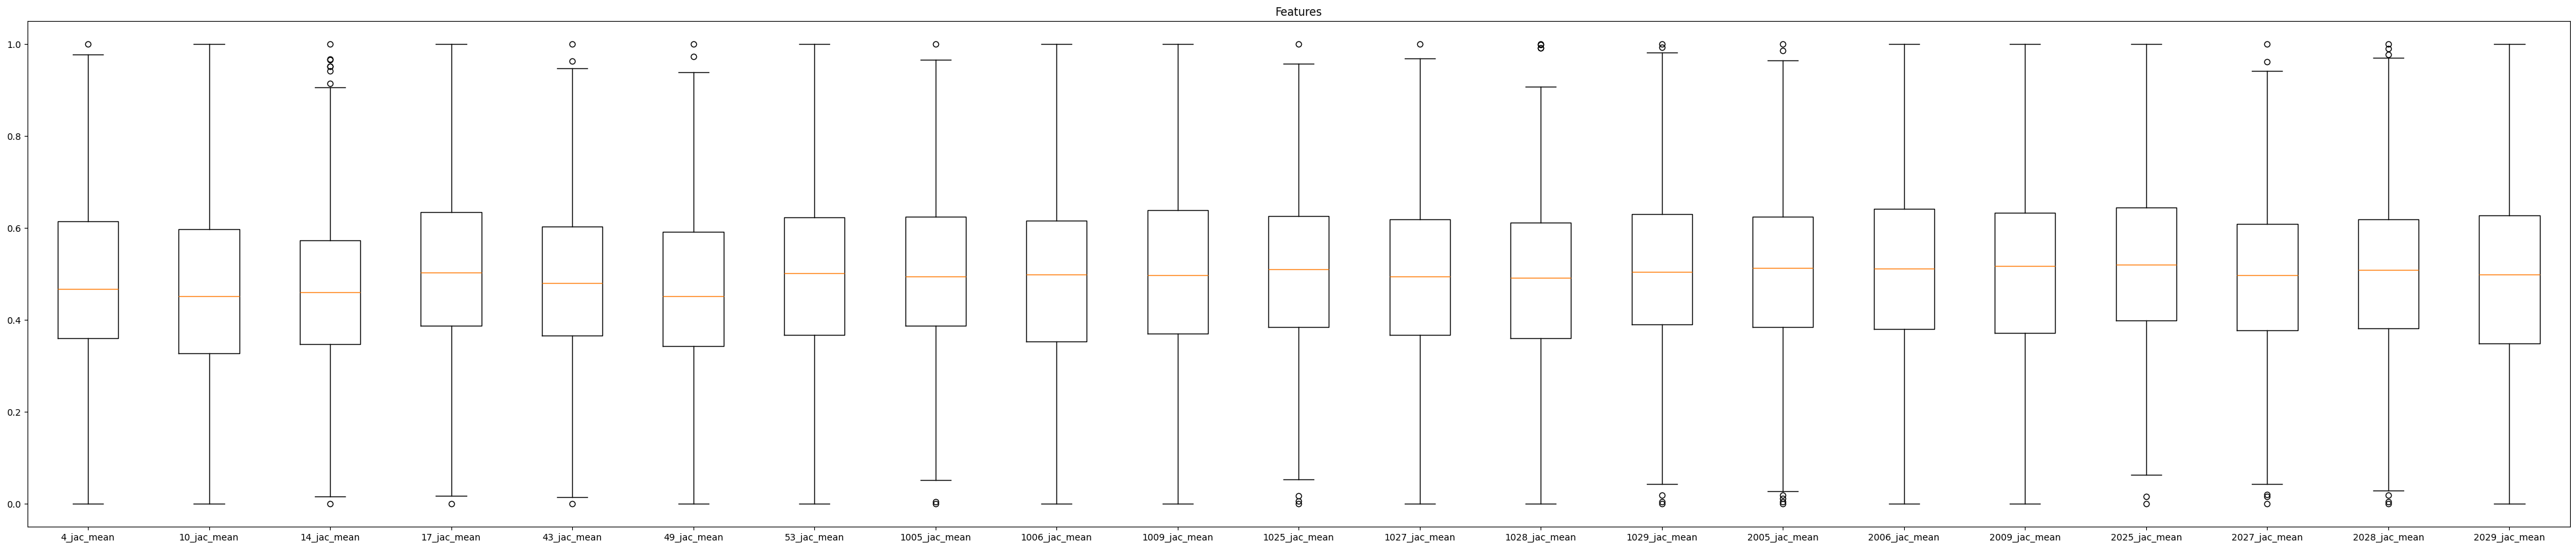

In [15]:
# # Standardize each column
# scaler = StandardScaler()
# data_standardized = scaler.fit_transform(data_no_outlayers)
# data_standardized_df = pd.DataFrame(data_standardized, columns=data_columns)

# # Normalize each column
# normalizer = MinMaxScaler()
# data_normalized = normalizer.fit_transform(data_standardized)
# data_normalized_df = pd.DataFrame(data_normalized, columns=data_columns)

data_standardized, standarizer = uml.standarize_columns(data_no_outlayers)
data_normalized, normalizer = uml.normalize_columns(data_standardized)
data_normalized_df = pd.DataFrame(data_normalized, columns=data_columns)

vis.plot_data_voxplot(data_standardized, data_columns, figsize=(50,10))
vis.plot_data_voxplot(data_normalized_df, data_columns, figsize=(50,10))


### Correlation

High correlated: []


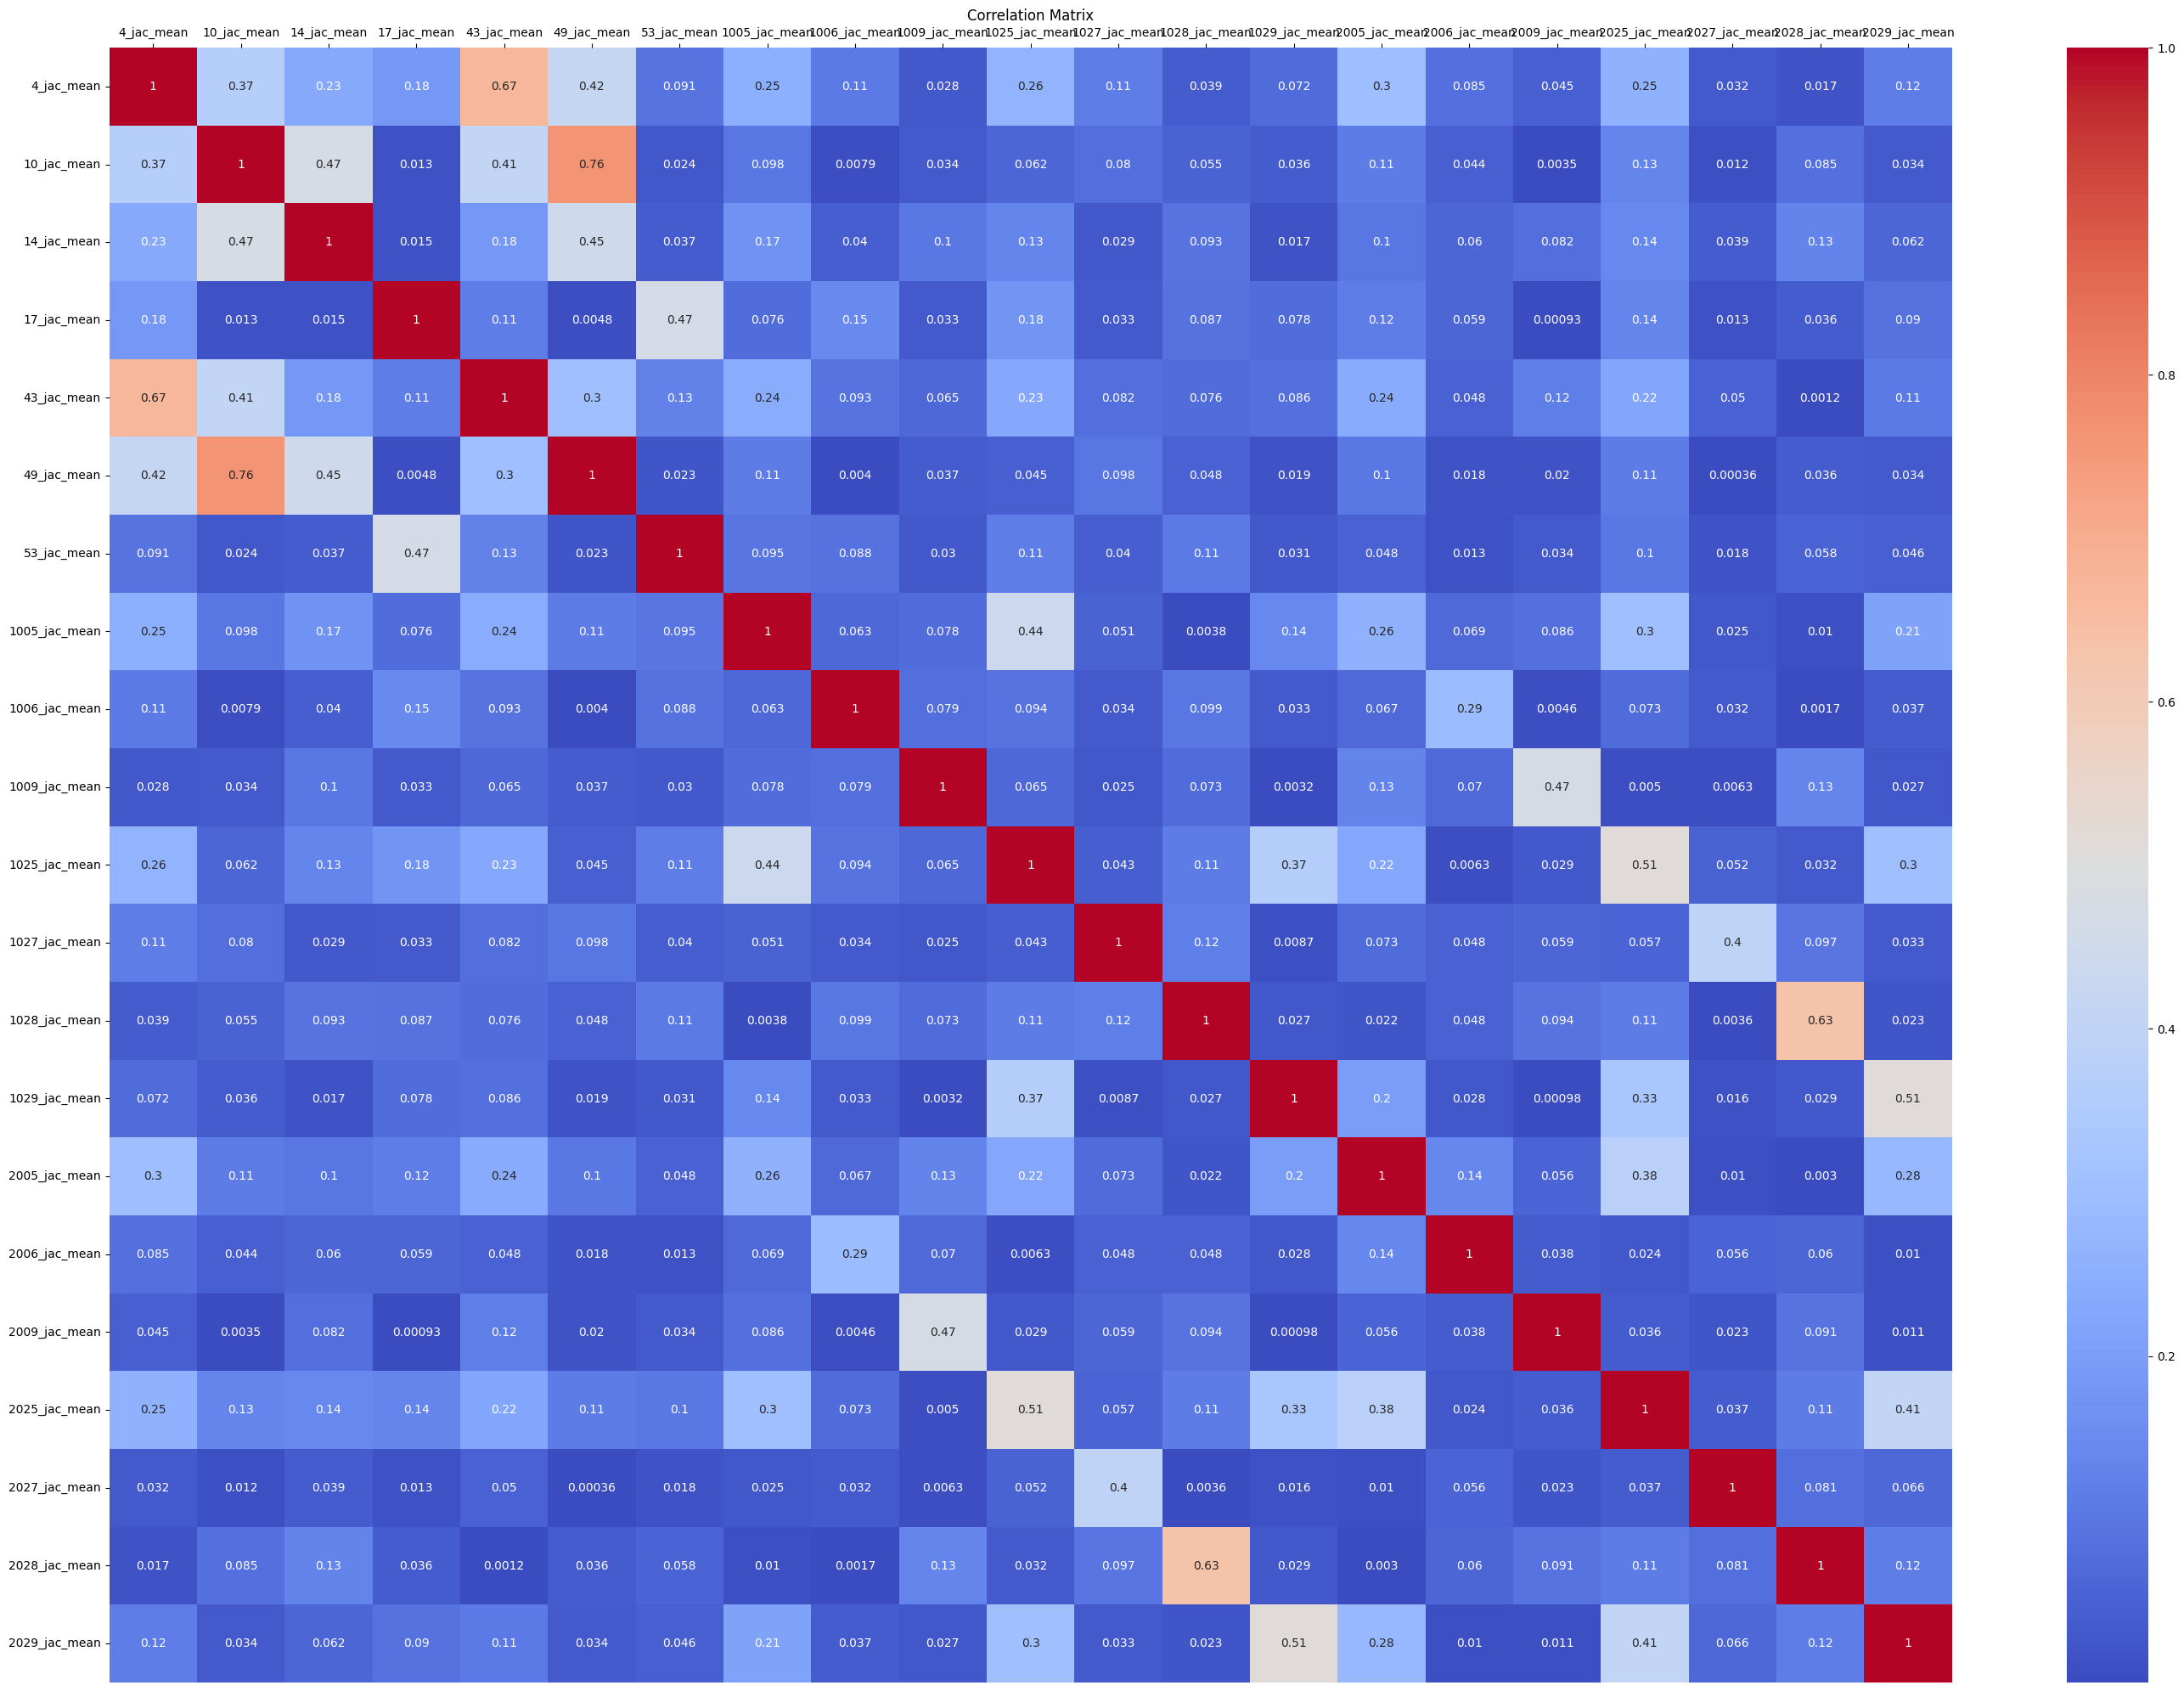

In [21]:
corr_df, to_drop = uml.correlation_df(data_normalized_df, corr_th=0.9)

print(f"High correlated: {to_drop}")
vis.plot_data_precomputed_correlation_df(corr_df, figsize=(35, 25))



### Visualize individual features

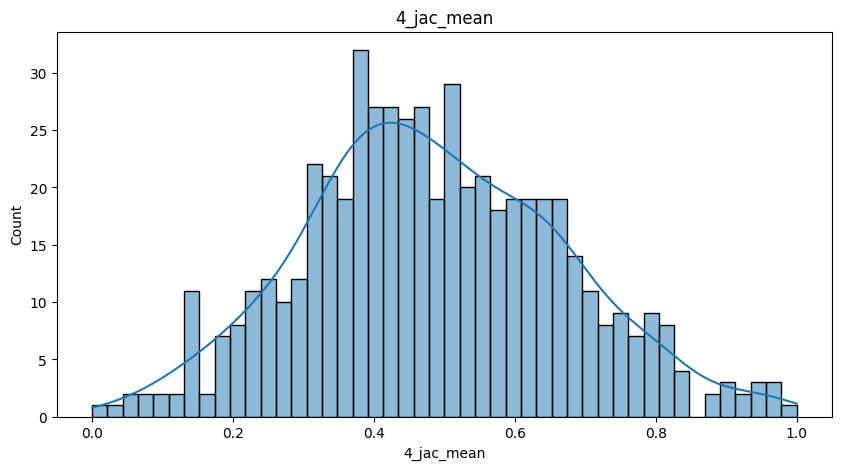

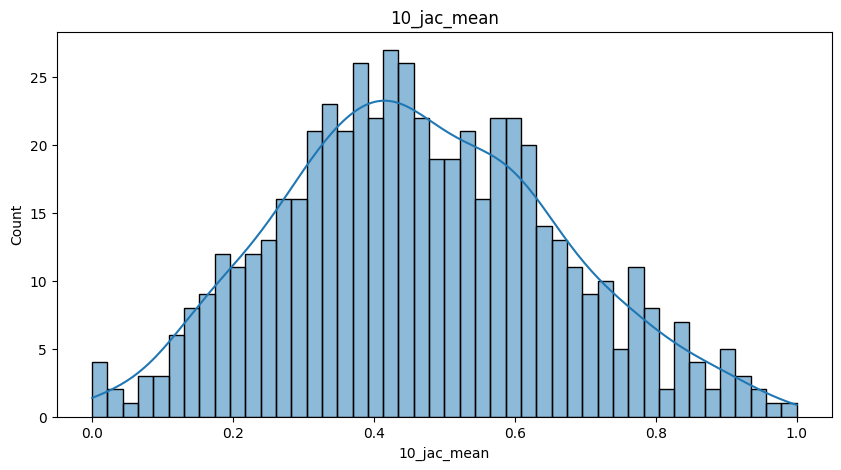

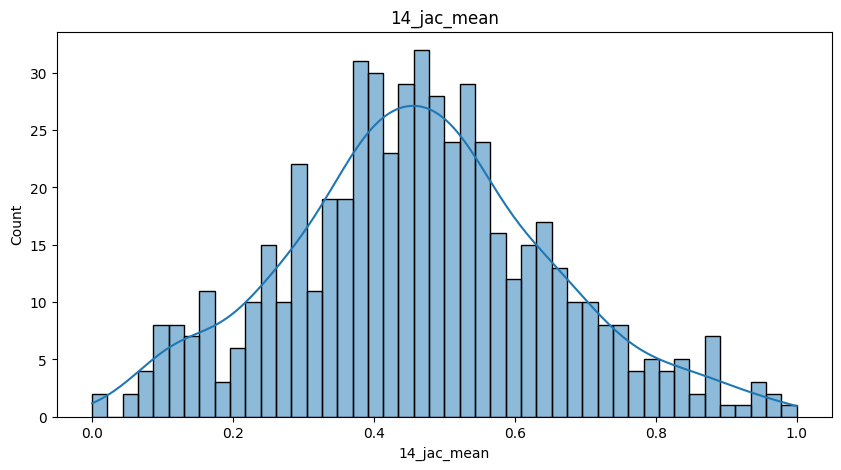

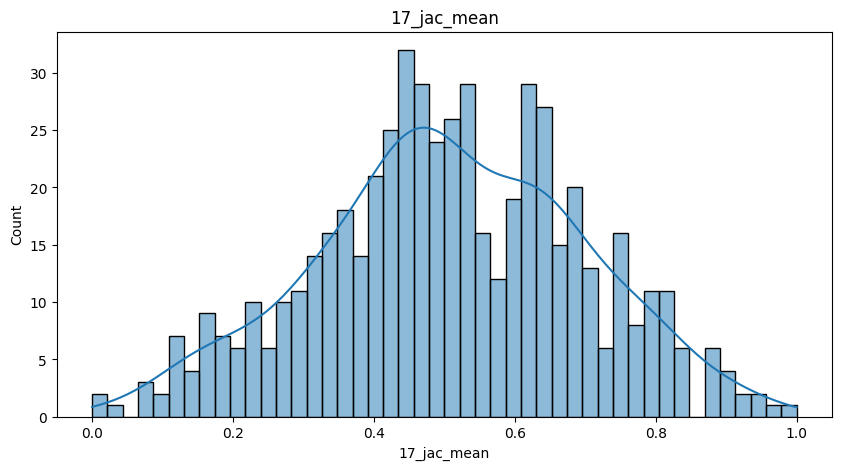

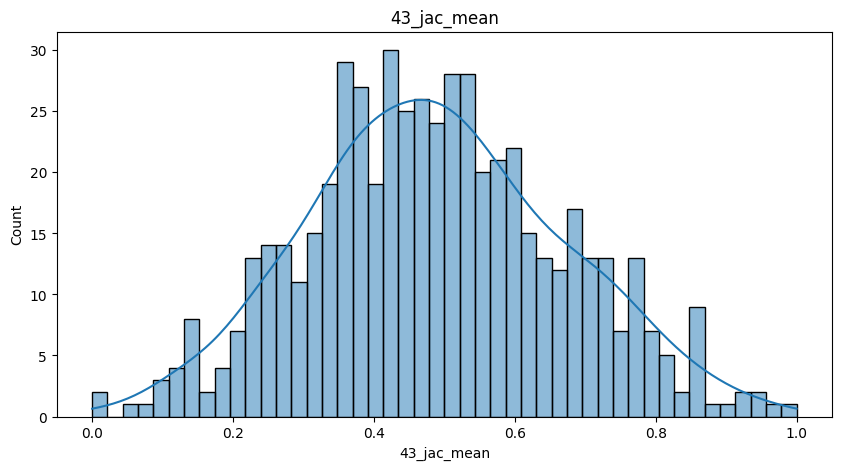

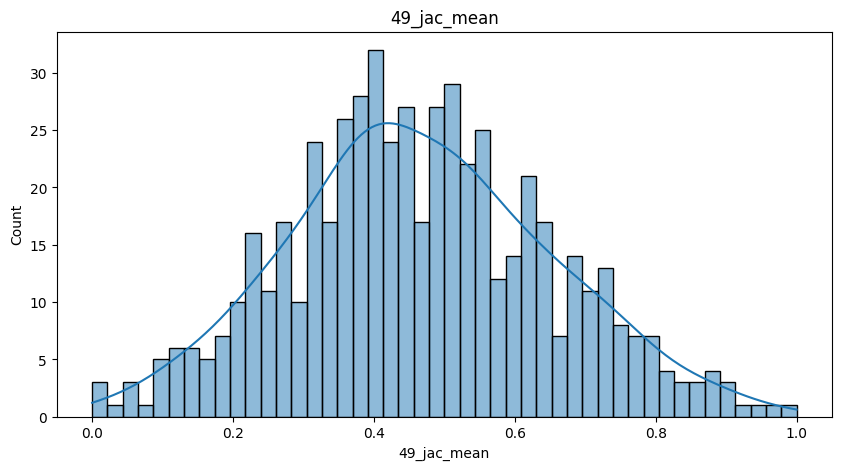

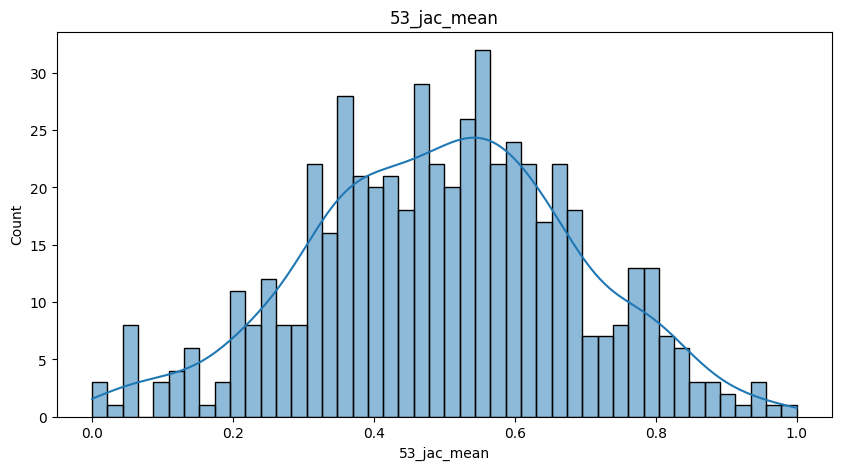

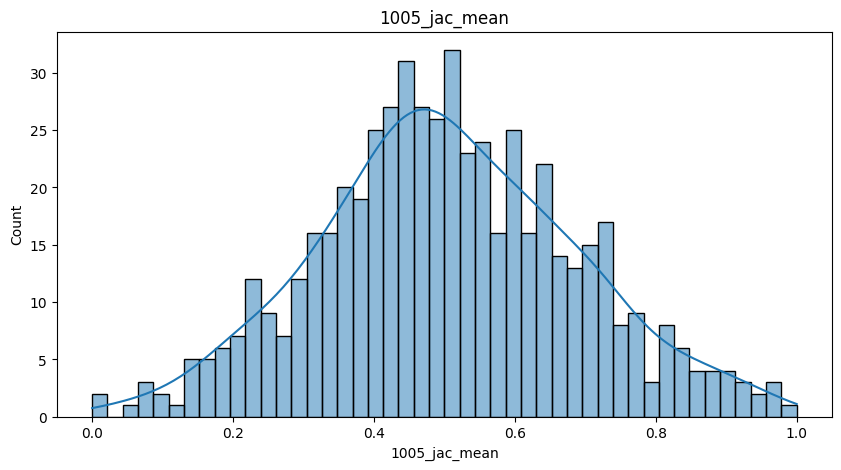

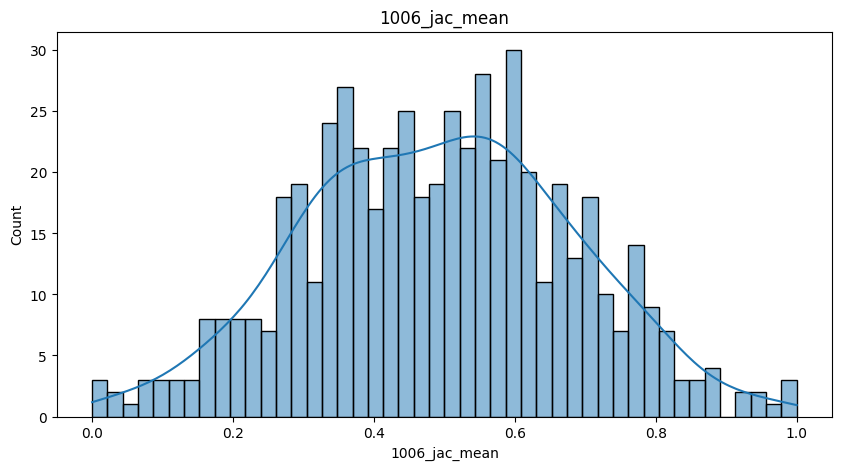

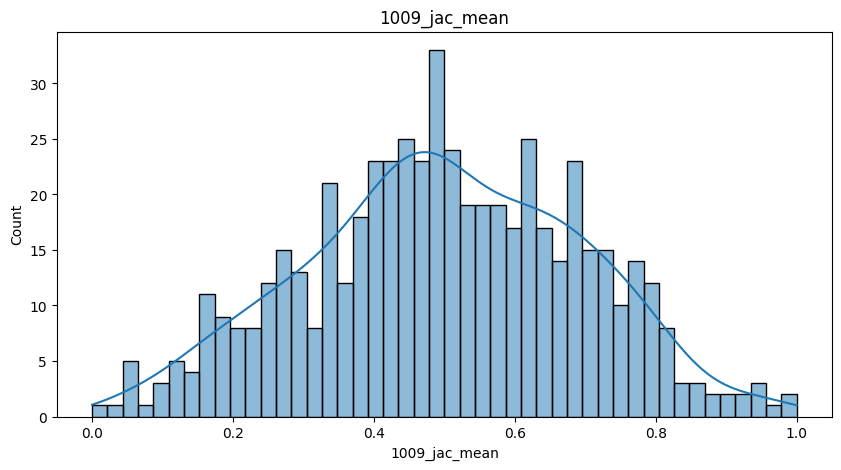

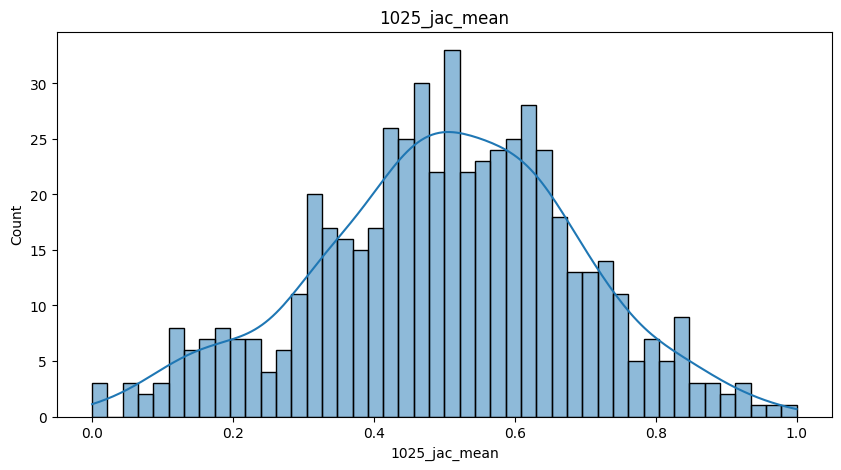

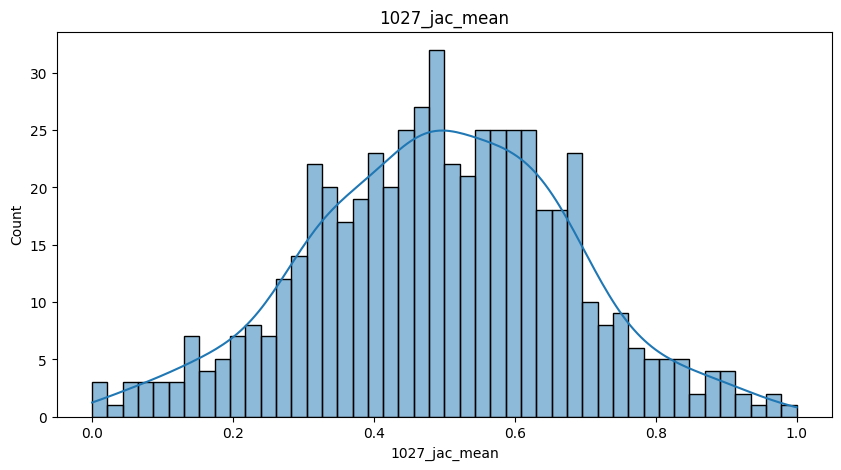

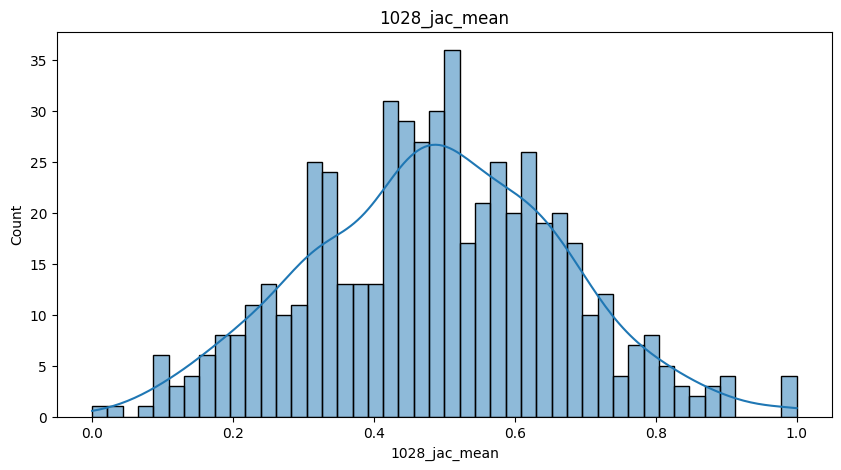

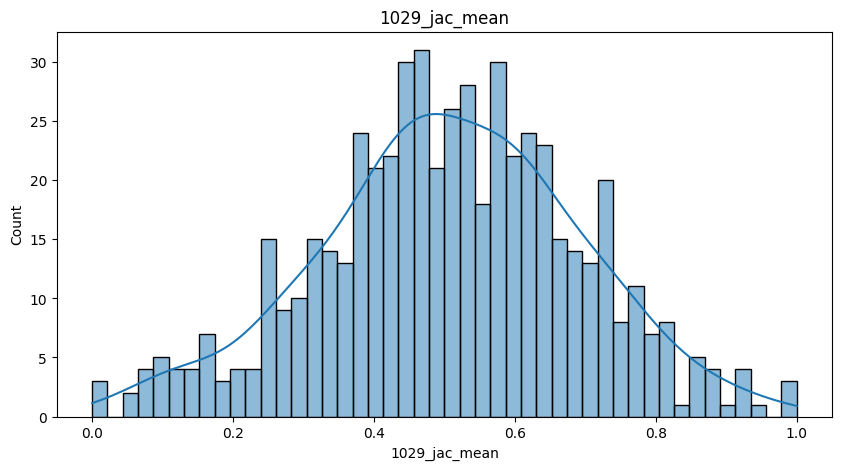

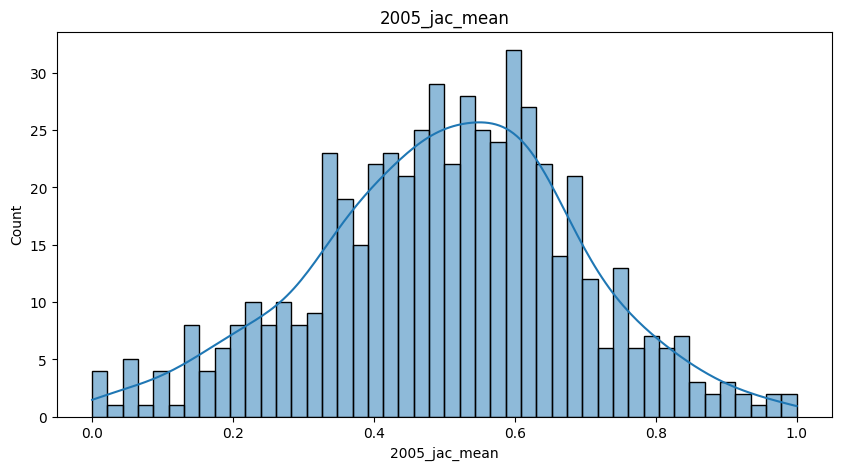

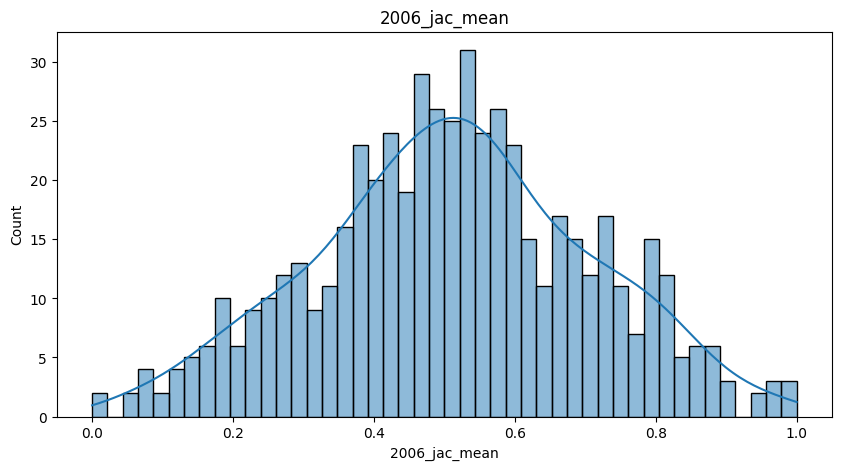

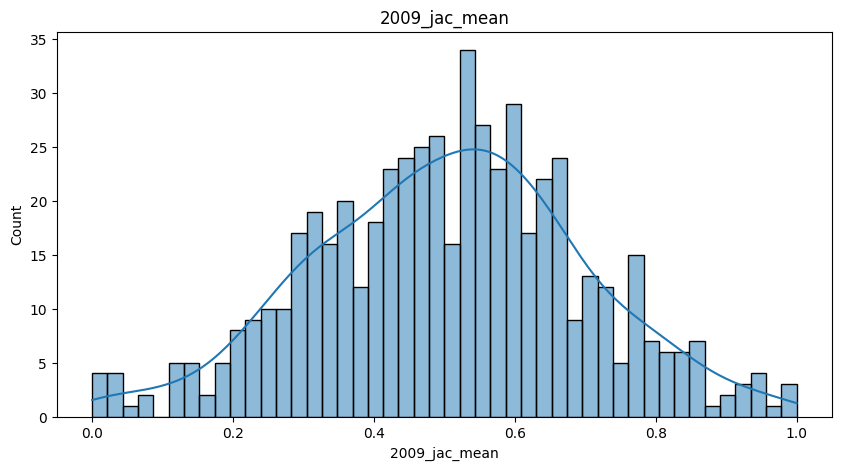

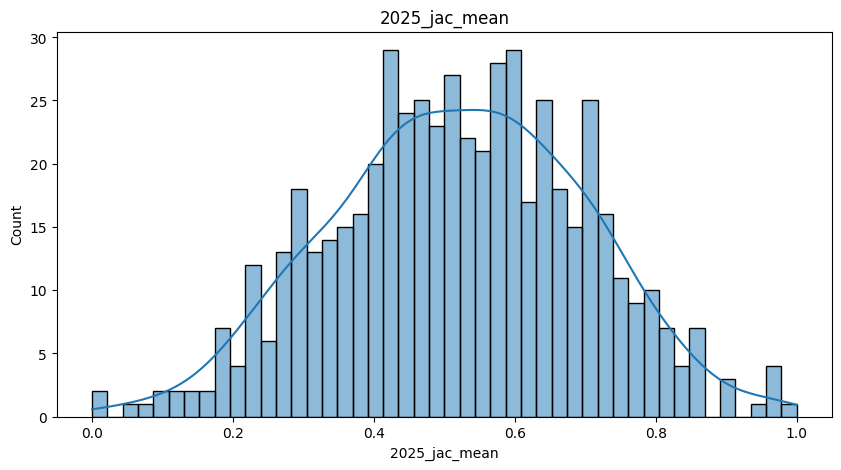

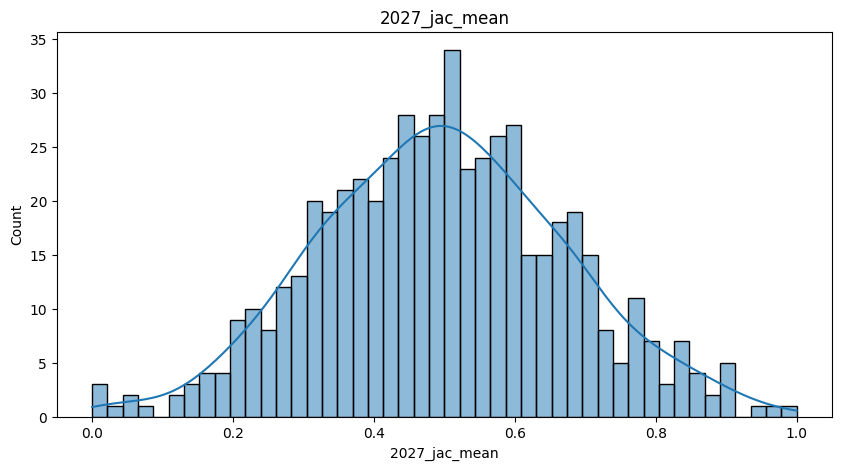

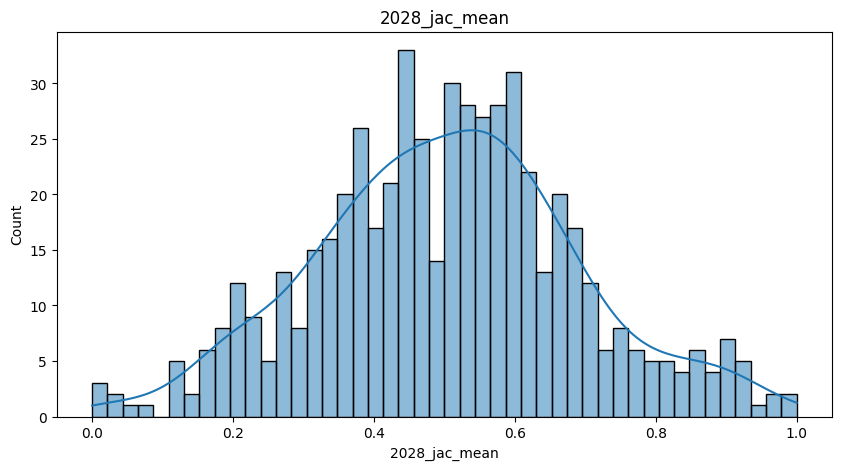

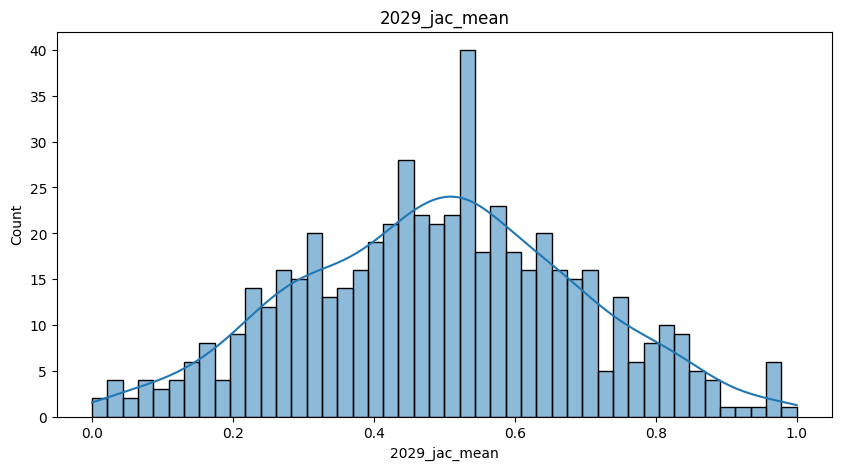

In [22]:
bins = int(np.sqrt(data_normalized.shape[0]))*2
# bins="auto"
binrange = (0.0,1.0)
data_to_hist_df = data_normalized_df

vis.plot_hist_all_data_df(data_to_hist_df, bins=bins, binrange=binrange, figsize=(10, 5))

### Visualize 2D

In [8]:
# vis.plot_2D_points_2v2_all_data_df(data_to_hist_df, figsize=(5, 5))

### PCA

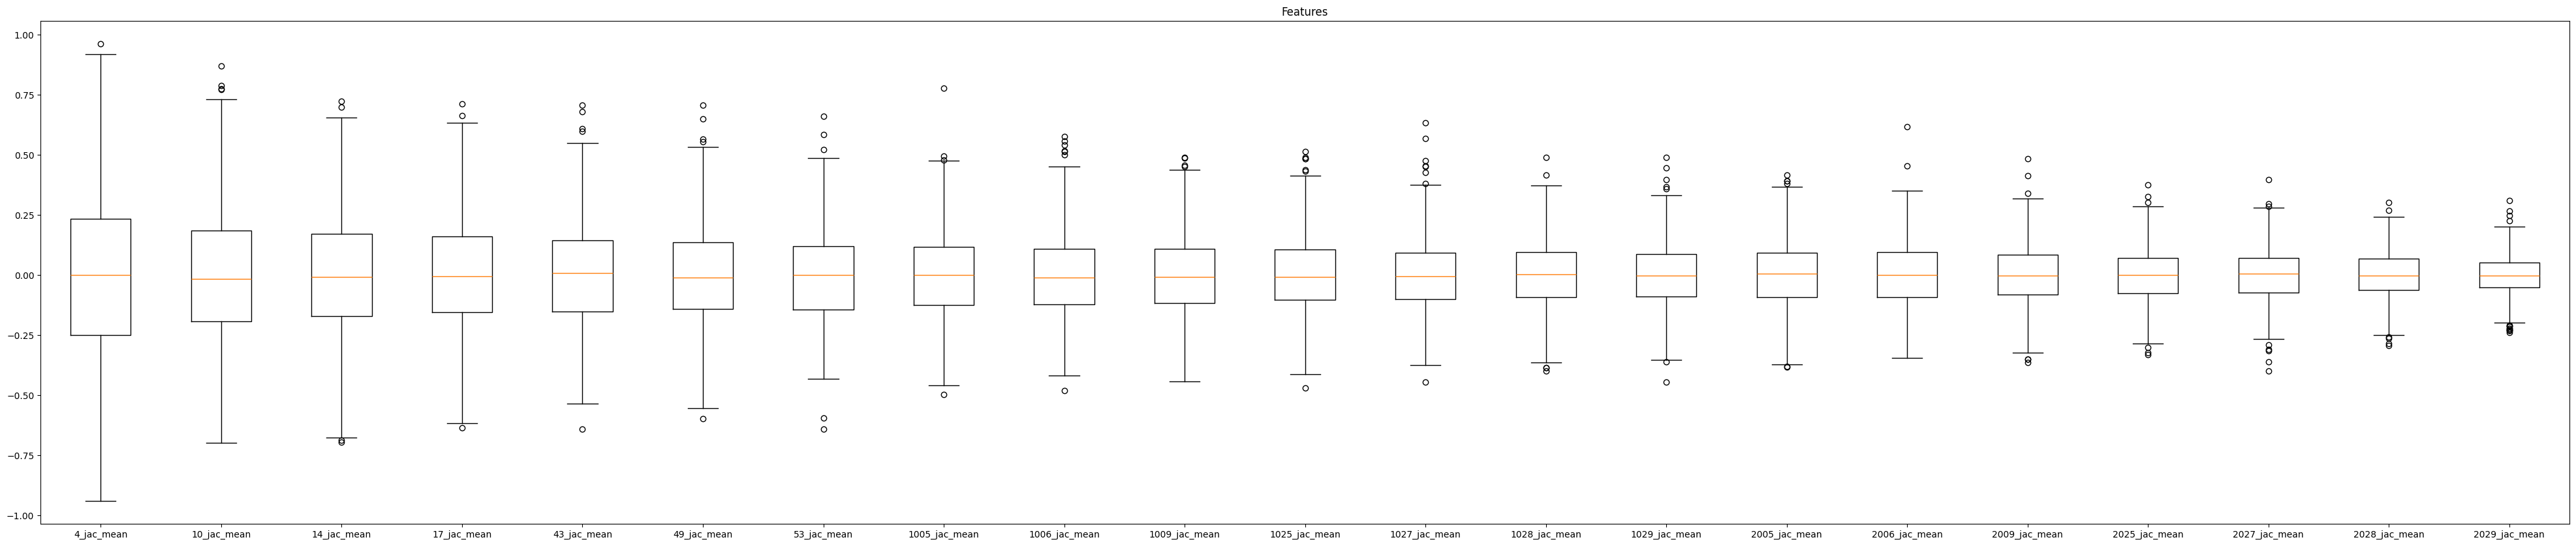

In [23]:
pca_obj = PCA(n_components=len(data_columns))
data_pca = pca_obj.fit_transform(data_normalized_df)

vis.plot_data_voxplot(data_pca, data_columns, figsize=(50,10))


# Clustering

In [ ]:
nb_clusters = 16
random_state = 42

def count_not_matching_clusters(clusters1, clusters2):
    count = 0
    for i in range(len(clusters1)):
        if clusters1[i] != clusters2[i]:
            count += 1
    return count

## K-means

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=nb_clusters, random_state=random_state)
clusters_kmeans = kmeans.fit_predict(data_pca)
# print(clusters_kmeans)
print(np.unique(np.array(clusters_kmeans), return_counts=True)[1])

# [34 10 33 19 19 26 28 19 29  3  5 21 24  9  9 15]
# [38 19 46 40  1 11  7 20 16 24 27 11 35  3  1  4]

[34 10 33 19 19 26 28 19 29  3  5 21 24  9  9 15]


## EM

In [ ]:
from sklearn.mixture import GaussianMixture

# Crear el objeto GaussianMixture
gmm = GaussianMixture(n_components=nb_clusters, random_state=random_state, init_params='kmeans', max_iter=10000, tol=1e-6)
clusters_em = gmm.fit_predict(data_pca)
print(np.unique(np.array(clusters_em), return_counts=True)[1])

count_not_matching_clusters(clusters_kmeans, clusters_em)


[35 10 33 19 19 25 28 19 29  3  5 21 24  9  9 15]


1

## Mean-shift

In [ ]:
from sklearn.cluster import MeanShift


clustering = MeanShift()
clustering.fit(data_pca)

# Obtener las etiquetas de los clusters y los centros de los clusters
clusters_meanshift = clustering.labels_
print(len(np.unique(clusters_meanshift)))
print(np.unique(np.array(clusters_meanshift), return_counts=True)[1])
# cluster_centers = clustering.cluster_centers_
# print(clusters_meanshift)


7
[293   4   2   1   1   1   1]


## DBSCAN

In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=7, min_samples=2)
dbscan.fit(data_pca)
clusters_dbscan = dbscan.labels_

print(len(np.unique(clusters_dbscan)))
print(np.unique(np.array(clusters_dbscan), return_counts=True)[1])

# print(clusters_dbscan)

1
[303]


# Clustering visualization

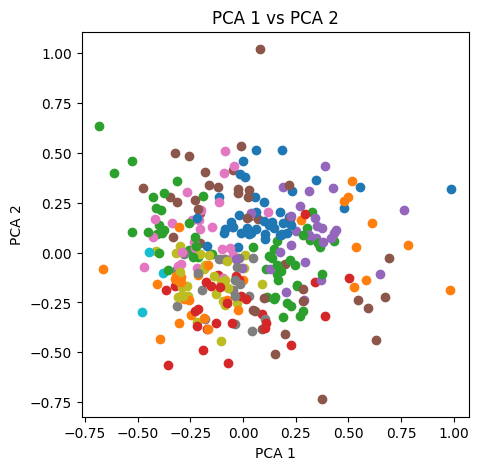

In [ ]:
# import matplotlib.pyplot as plt


# # Obtener las coordenadas de los componentes principales
# x = data_pca[:, 0]
# y = data_pca[:, 1]

# # Crear una figura y un conjunto de ejes
# fig, ax = plt.subplots()

# # Iterar sobre los elementos y asignar un color diferente a cada cluster
# for i, cluster in enumerate(clusters_kmeans):
#     # Obtener el color correspondiente al cluster
#     color = 'C{}'.format(cluster)
    
#     # Plotear el punto con el color correspondiente
#     ax.scatter(x[i], y[i], color=color)

# # Mostrar el gráfico
# plt.show()

cluster = clusters_em

vis.plot_2D_points(data_pca[:, 0], data_pca[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))
# plot_points(data_normalized[:, 0], data_normalized[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))
# plot_points(data_standardized[:, 0], data_standardized[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))
# plot_points(data.values[:, 0], data.values[:, 1], 'PCA 1', 'PCA 2', cluster, figsize=(5, 5))

# Save clustering

In [ ]:
data_ids
clusters_em

df = pd.DataFrame({'patient_id': data_ids, 'cluster_em': clusters_em, 'cluster_kmeans': clusters_kmeans, 'cluster_meanshift': clusters_meanshift, 'cluster_dbscan': clusters_dbscan})
df = df.astype(int)

df_name = f'C{nb_clusters}_T{nb_tissues}_{"-".join(metrics_name)}.csv'
# df.to_csv(f'{current_path}/clusters/{df_name}', index=False)